# AequilibraE monthly PyPI downloads

Put both CSV files beside this notebook in `misc/` and run all cells. Use these column names in the header row.

- `downloads.csv` needs `Downloads` and `Month`.
- `versions.csv` needs `version` and `upload_time`.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [4]:
# Use the notebook folder when running from the repository root.
csv_dir = Path("misc") if Path("misc/pypi.ipynb").is_file() else Path.cwd()

In [5]:
# BigQuery SQL for exporting downloads.csv
# SELECT
#     COUNT(*) AS Downloads,
#     TIMESTAMP_TRUNC(timestamp, MONTH) AS Month
# FROM `bigquery-public-data.pypi.file_downloads`
# WHERE file.project = 'aequilibrae'
# GROUP BY Month
# ORDER BY Month

df = pd.read_csv(csv_dir / "downloads.csv")
df["Month"] = pd.to_datetime(df["Month"], format="mixed", utc=True)
df

,Downloads,Month
0,702,2018-10-01 00:00:00+00:00
1,403,2018-11-01 00:00:00+00:00
2,312,2018-12-01 00:00:00+00:00
3,339,2019-01-01 00:00:00+00:00
4,288,2019-02-01 00:00:00+00:00
...,...,...
93,16751,2026-07-01 00:00:00+00:00
94,34227,2026-08-01 00:00:00+00:00
95,16044,2026-09-01 00:00:00+00:00
96,26506,2026-10-01 00:00:00+00:00


In [6]:
df["Downloads"].sum()

np.int64(1466266)

In [7]:
# BigQuery SQL for exporting versions.csv
# SELECT version, MIN(upload_time) AS upload_time
# FROM `bigquery-public-data.pypi.distribution_metadata`
# WHERE LOWER(name) = 'aequilibrae'
# GROUP BY version
# ORDER BY upload_time, version

versions_df = pd.read_csv(csv_dir / "versions.csv", dtype={"version": str})
versions_df["upload_time"] = pd.to_datetime(
    versions_df["upload_time"], format="mixed", utc=True
)
versions_df = versions_df.sort_values("upload_time")
versions_df = versions_df[~versions_df["version"].str.contains("dev")]

# Keep the first release for each major and minor version.
versions_df = versions_df.loc[
    versions_df["version"].str.rpartition(".")[0].drop_duplicates(keep="first").index
]
versions_df

,version,upload_time
0,0.5.0,2018-10-21 10:56:58.123572+00:00
3,0.6.0,2020-02-07 03:06:05.692205+00:00
9,0.7.0,2021-01-14 09:19:09.030090+00:00
17,0.8.0,2023-01-16 13:31:56.044625+00:00
27,0.9.0,2023-04-28 10:25:54.040737+00:00
39,1.0.0,2023-12-16 11:37:19.939977+00:00
42,1.1.0,2024-07-27 00:21:18.372545+00:00
48,1.2.0,2025-03-03 06:41:47.860643+00:00
49,1.3.0,2025-04-30 22:16:49.716411+00:00
51,1.4.0,2025-05-23 12:02:10.392691+00:00


Text(0.5, 1.0, 'AequilibraE PyPI downloads by month')

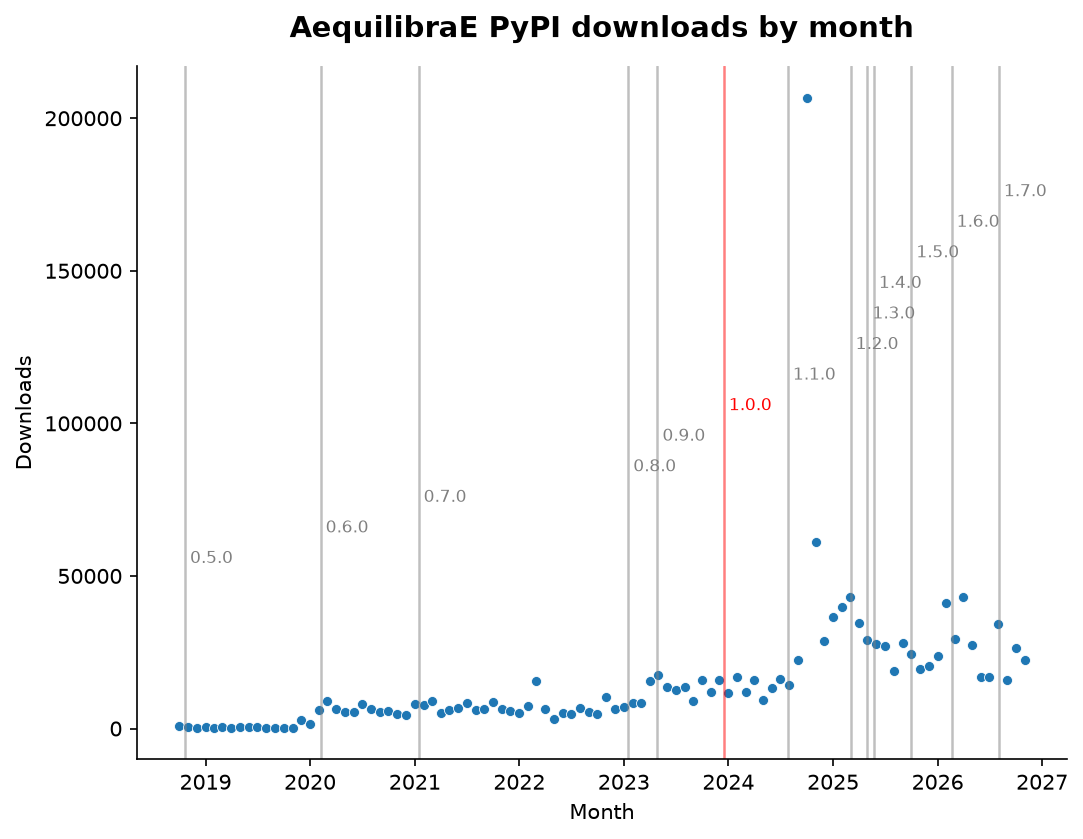

In [8]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

sns.set_theme(style="whitegrid", context="paper")

sns.scatterplot(data=df, x="Month", y="Downloads", ax=ax)
# ax.set_ylim((0, 100_000))

for i, (_, row) in enumerate(versions_df.iterrows()):
    colour = "red" if row["version"] in {"1.0.0"} else "grey"
    ax.axvline(row["upload_time"], color=colour, linestyle="-", alpha=0.5)
    ax.text(
        row["upload_time"],
        ax.get_ylim()[1] * (0.25 + 0.6 * i / len(versions_df)),
        " " + row["version"],
        fontsize=8,
        color=colour,
    )

sns.despine(right=True, top=True)
ax.set_title(
    "AequilibraE PyPI downloads by month", pad=14, fontweight="bold", fontsize=14
)